In [17]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

In [18]:
# The filename of the processed dictionary data
file_path = 'amsterdam_juridisch_woordenboek_processed.csv'

# Read the CSV file
df = pd.read_csv(file_path)

# The 'Simplified_List' column is currently stored as a string representation of a list.
# We use ast.literal_eval to safely convert this string back into a Python list object.
try:
    df['Simplified_List'] = df['Simplified_List'].apply(ast.literal_eval)
    print("Successfully converted 'Simplified_List' column from string to list.")
except ValueError:
    print("Error: Could not convert 'Simplified_List'. Check for malformed list strings.")
    
df.head()

Successfully converted 'Simplified_List' column from string to list.


,Word,Simplified,Simplified_List
0,aan de hand van,1. met; 2. door,"[met, door]"
1,a priori,vooraf,[vooraf]
2,aanbieden (van afval),neerzetten,[neerzetten]
3,aandachtig,goed,[goed]
4,aangaande,over,[over]


In [19]:
print(f"Total entries in the dictionary: {len(df)}")
print("\nDataFrame Information")
df.info()

# Check for any missing values
print("\nMissing Values Check")
print(df.isnull().sum())

Total entries in the dictionary: 746

DataFrame Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 746 entries, 0 to 745
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Word             746 non-null    object
 1   Simplified       746 non-null    object
 2   Simplified_List  746 non-null    object
dtypes: object(3)
memory usage: 17.6+ KB

Missing Values Check
Word               0
Simplified         0
Simplified_List    0
dtype: int64


In [20]:
# Calculate the number of simplified alternatives for each word
df['Num_Alternatives'] = df['Simplified_List'].apply(len)

print("First few rows with the new 'Num_Alternatives' column:")
print(df[['Word', 'Simplified_List', 'Num_Alternatives']].head().to_markdown(index=False))

First few rows with the new 'Num_Alternatives' column:
| Word                  | Simplified_List   |   Num_Alternatives |
|:----------------------|:------------------|-------------------:|
| aan de hand van       | ['met', 'door']   |                  2 |
| a priori              | ['vooraf']        |                  1 |
| aanbieden (van afval) | ['neerzetten']    |                  1 |
| aandachtig            | ['goed']          |                  1 |
| aangaande             | ['over']          |                  1 |


In [21]:
print("Summary Statistics for Number of Alternatives")
print(df['Num_Alternatives'].describe().to_markdown())

# Find the words with the most alternatives (the most complex simplification)
most_complex = df.sort_values(by='Num_Alternatives', ascending=False).head(5)
print("\nTop 5 Words with Most Alternatives")
print(most_complex[['Word', 'Num_Alternatives']].to_markdown(index=False))

Summary Statistics for Number of Alternatives
|       |   Num_Alternatives |
|:------|-------------------:|
| count |         746        |
| mean  |           1.62601  |
| std   |           0.781202 |
| min   |           1        |
| 25%   |           1        |
| 50%   |           1        |
| 75%   |           2        |
| max   |           6        |

Top 5 Words with Most Alternatives
| Word         |   Num_Alternatives |
|:-------------|-------------------:|
| ontwikkelen  |                  6 |
| tool         |                  5 |
| vermelden    |                  5 |
| participeren |                  5 |
| documenteren |                  5 |


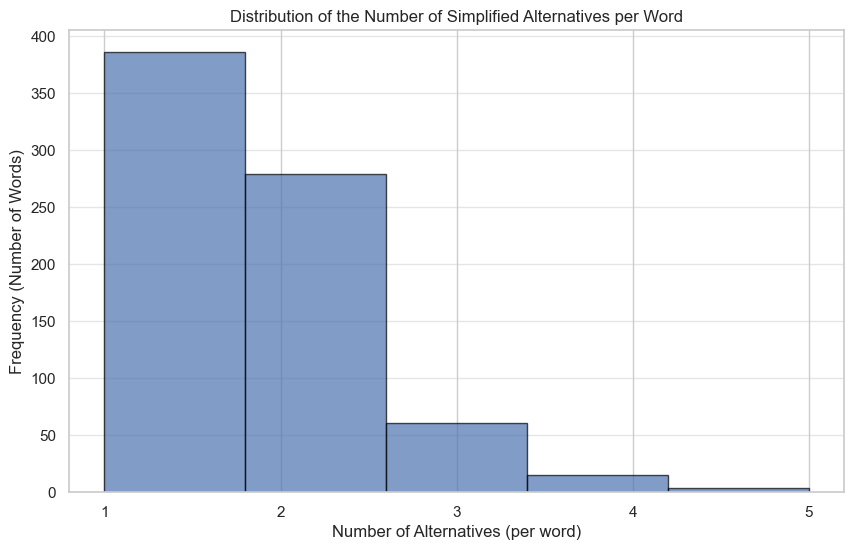


51.74% of the words have exactly one simplified alternative.


In [22]:
plt.figure(figsize=(10, 6))
# Only consider words with up to 5 alternatives for a clearer visual, as outliers skew the plot.
plot_data = df[df['Num_Alternatives'] <= 5]['Num_Alternatives']

# Create a histogram to show the distribution of the number of alternatives
plot_data.plot(kind='hist', bins=plot_data.max(), edgecolor='black', alpha=0.7)

plt.title('Distribution of the Number of Simplified Alternatives per Word')
plt.xlabel('Number of Alternatives (per word)')
plt.ylabel('Frequency (Number of Words)')
plt.xticks(range(1, int(plot_data.max()) + 1))
plt.grid(axis='y', alpha=0.5)

plt.show()

# Check percentage of words that only have one alternative
single_alternative_percent = (df['Num_Alternatives'] == 1).mean() * 100
print(f"\n{single_alternative_percent:.2f}% of the words have exactly one simplified alternative.")

In [23]:
# --- Word Length and Simplification Analysis ---

# Calculate length metrics (using word count as a proxy for complexity)
# Word count for original term
df['Word_Word_Count'] = df['Word'].apply(lambda x: len(str(x).split()))

# Average word count for all alternatives combined
def get_avg_alt_word_count(alt_list):
    if not alt_list:
        return 0
    total_words = sum(len(str(alt).split()) for alt in alt_list)
    return total_words / len(alt_list)

df['Avg_Simplified_Word_Count'] = df['Simplified_List'].apply(get_avg_alt_word_count)

# Calculate Simplification Ratio: (Avg Simplified Word Count / Original Word Count)
# Ratio < 1 means the simplified terms are shorter on average.
df['Simplification_Ratio'] = df['Avg_Simplified_Word_Count'] / df['Word_Word_Count']

print("--- Summary Statistics for Simplification Ratio ---")
print(df['Simplification_Ratio'].describe().to_markdown())

# Top 5 most 'simplified' terms (lowest ratio)
most_simplified = df.sort_values(by='Simplification_Ratio').head(5)
print("\n--- Top 5 Words with Highest Simplification (Lowest Ratio) ---")
print(most_simplified[['Word', 'Word_Word_Count', 'Avg_Simplified_Word_Count', 'Simplification_Ratio']].to_markdown(index=False))

# Bottom 5 least 'simplified' terms (ratio near 1 or > 1)
least_simplified = df.sort_values(by='Simplification_Ratio', ascending=False).head(5)
print("\n--- Top 5 Words with Lowest Simplification (Highest Ratio) ---")
print(least_simplified[['Word', 'Word_Word_Count', 'Avg_Simplified_Word_Count', 'Simplification_Ratio']].to_markdown(index=False))

--- Summary Statistics for Simplification Ratio ---
|       |   Simplification_Ratio |
|:------|-----------------------:|
| count |             746        |
| mean  |               1.22667  |
| std   |               0.923067 |
| min   |               0.111111 |
| 25%   |               1        |
| 50%   |               1        |
| 75%   |               1.33333  |
| max   |               9        |

--- Top 5 Words with Highest Simplification (Lowest Ratio) ---
| Word                              |   Word_Word_Count |   Avg_Simplified_Word_Count |   Simplification_Ratio |
|:----------------------------------|------------------:|----------------------------:|-----------------------:|
| om de reden dat / om de reden van |                 9 |                         1   |               0.111111 |
| op grond van het voorgaande       |                 5 |                         1   |               0.2      |
| gelet op (het feit dat)           |                 5 |                         

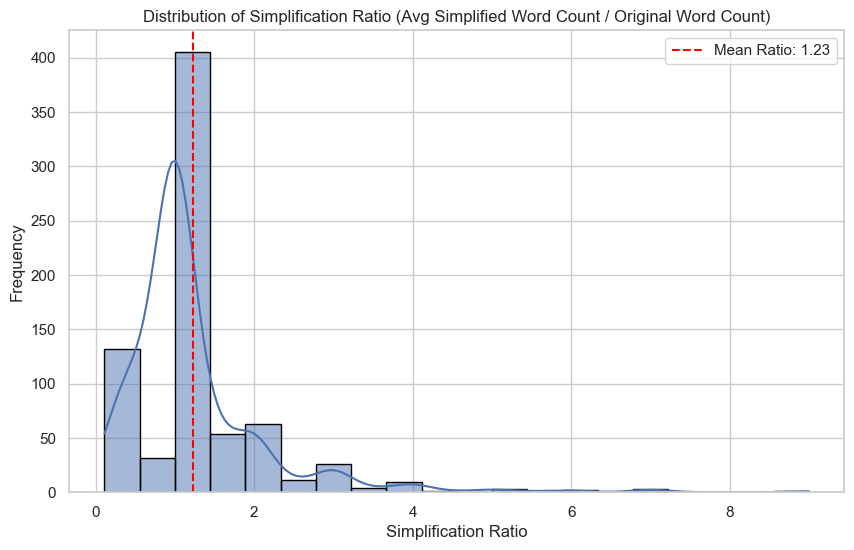

In [24]:
plt.figure(figsize=(10, 6))
# Plotting the distribution of the Simplification Ratio
sns.histplot(df['Simplification_Ratio'], bins=20, kde=True, edgecolor='black')

plt.title('Distribution of Simplification Ratio (Avg Simplified Word Count / Original Word Count)')
plt.xlabel('Simplification Ratio')
plt.ylabel('Frequency')
plt.axvline(df['Simplification_Ratio'].mean(), color='red', linestyle='--', label=f'Mean Ratio: {df["Simplification_Ratio"].mean():.2f}')
plt.legend()
plt.show()

--- Top 20 Most Frequent Simplified Alternatives (Vocabulary Check) ---


/var/folders/cg/kt7bgnmj3_jb1z7xmpjhgtpw0000gn/T/ipykernel_93391/3628486510.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_20.index, y=top_20.values, palette="viridis")


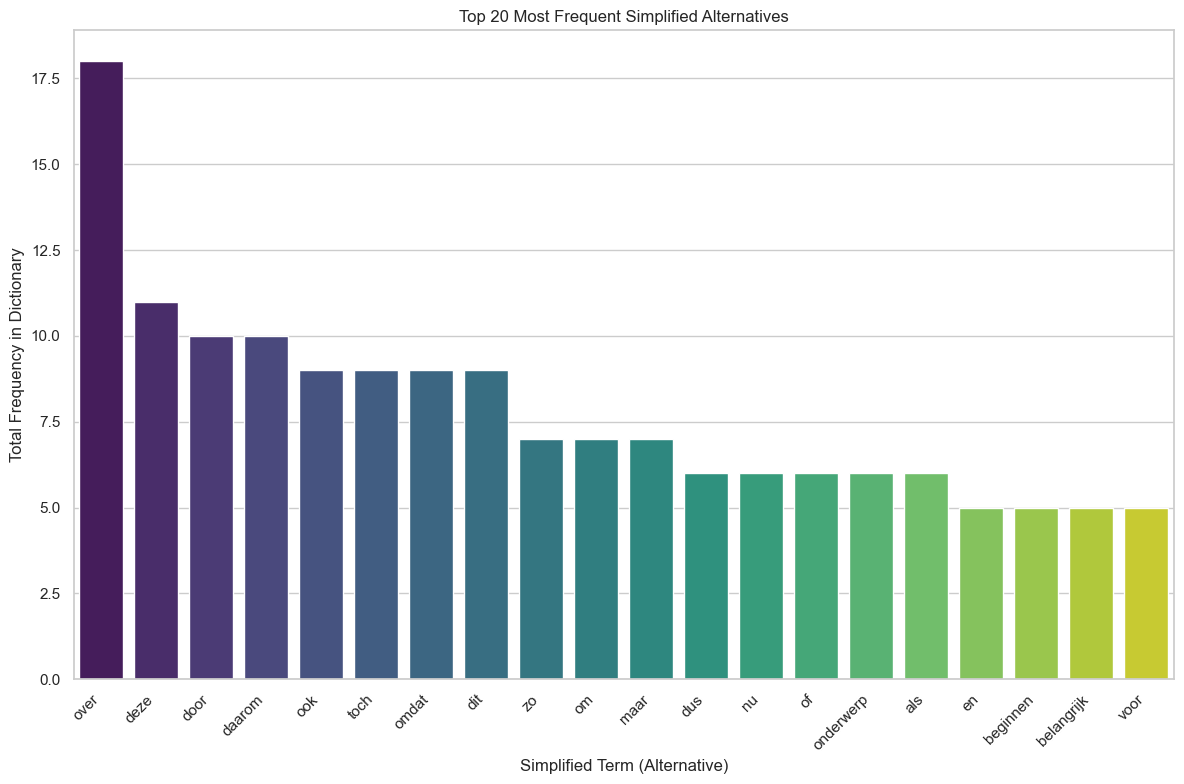

In [ ]:
# --- Most Frequent Simplified Alternatives Analysis ---

# Explode the list column to get one row per alternative
alternatives_exploded = df.explode('Simplified_List')

# Clean up the alternative text (lowercase and strip whitespace)
alternatives_exploded['Alternative'] = alternatives_exploded['Simplified_List'].str.lower().str.strip()

# Count the frequency of each unique alternative
alternative_counts = alternatives_exploded['Alternative'].value_counts()

print("Top 20 Most Frequent Simplified Alternatives (Vocabulary Check)")
# Display as a bar chart for better visualization
plt.figure(figsize=(12, 8))
top_20 = alternative_counts.head(20)
sns.barplot(x=top_20.index, y=top_20.values, palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.title('Top 20 Most Frequent Simplified Alternatives')
plt.xlabel('Simplified Term (Alternative)')
plt.ylabel('Total Frequency in Dictionary')
plt.tight_layout()
plt.show()